# 01 · Fase 1: busca léxica no OpenSearch


In [1]:
from pathlib import Path
import sys, json, shutil
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "ri_core.py").is_file()), None)
assert ROOT is not None, "Extraia o pacote e abra o notebook a partir da sua pasta."
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from ri_core import load_data, load_qrels, load_run, evaluate, write_json, write_csv
from ri_workflow import *
print("Raiz do pacote:", ROOT)

Raiz do pacote: /home/oliveirat/disciplinas/reqinfo/RecInfo/lab_ri_opensearch


In [14]:
pip install pandas matplotlib

  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.9/9.9 MB 54.3 MB/s  0:00:00
Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.7/6.7 MB 67.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 54.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.1/7.1 MB 60.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7/7 [matplotlib] 6/7 [matplotlib]ow]
Note: you may need to restart the kernel to use updated packages.


Pré-requisito: notebook 00 homologado, OpenSearch 3.9.0 em execução.
 Entrada: corpus e consultas públicos. Saídas: índice, ranking e métricas de validação.
 Para repetir um experimento use novo `EXPERIMENT`, pois índices e pastas existentes não são apagados.

In [2]:
from os_retrieval import run_experiment, OpenSearchHTTP
TEAM = "equipe_16"
CONFIG = json.loads((ROOT / "starter/config.json").read_text(encoding="utf-8"))
CONFIG.update(team_id=TEAM, mode="lexical", analyzer="portuguese", bm25_k1=1.2, bm25_b=.75)
DATA = ROOT / "data/dev"
OUT = ROOT / "resultados" / f"{TEAM}_{EXPERIMENT}"
INDEX = f"ri-{TEAM}-{EXPERIMENT}"
OpenSearchHTTP().check()

{'name': '7e175bddd54f',
 'cluster_name': 'docker-cluster',
 'cluster_uuid': 'Iy0FclX_RZSx_NQPFUjL3g',
 'version': {'distribution': 'opensearch',
  'number': '3.9.0',
  'build_type': 'tar',
  'build_hash': '4ee42a94e87f66fbf1e62a9871b1b87f91e02472',
  'build_date': '2026-09-23T01:01:31.883915140Z',
  'build_snapshot': False,
  'lucene_version': '10.5.1',
  'minimum_wire_compatibility_version': '2.19.0',
  'minimum_index_compatibility_version': '2.0.0'},
 'tagline': 'The OpenSearch Project: https://opensearch.org/'}

In [3]:
from os_retrieval import run_experiment, OpenSearchHTTP
import csv

TEAM = "equipe_16"
DATA = ROOT / "data/dev"
COMPARISON = ROOT / "resultados/comparison_lab4.csv"
BASE_CONFIG = json.loads((ROOT / "starter/config.json").read_text(encoding="utf-8"))

OpenSearchHTTP().check()
docs, queries = load_data(DATA)
qrels = load_qrels(DATA / "qrels.csv", docs, queries)

In [10]:
from itertools import product

ANALYZERS = ["portuguese", "standard"]
K1_VALUES = [0.9, 1.2, 1.6, 2.0]
B_VALUES  = [0.5, 0.75, 0.9, 1.0]

def make_name(analyzer, k1, b):
    return f"{analyzer[:3]}_k{round(k1*10):02d}_b{round(b*100):03d}"

EXPERIMENTS = {
    make_name(a, k1, b): dict(analyzer=a, bm25_k1=k1, bm25_b=b)
    for a, k1, b in product(ANALYZERS, K1_VALUES, B_VALUES)
}
print(len(EXPERIMENTS), "experimentos")
for k,v in EXPERIMENTS.items():
    print(k,v)

32 experimentos
por_k09_b050 {'analyzer': 'portuguese', 'bm25_k1': 0.9, 'bm25_b': 0.5}
por_k09_b075 {'analyzer': 'portuguese', 'bm25_k1': 0.9, 'bm25_b': 0.75}
por_k09_b090 {'analyzer': 'portuguese', 'bm25_k1': 0.9, 'bm25_b': 0.9}
por_k09_b100 {'analyzer': 'portuguese', 'bm25_k1': 0.9, 'bm25_b': 1.0}
por_k12_b050 {'analyzer': 'portuguese', 'bm25_k1': 1.2, 'bm25_b': 0.5}
por_k12_b075 {'analyzer': 'portuguese', 'bm25_k1': 1.2, 'bm25_b': 0.75}
por_k12_b090 {'analyzer': 'portuguese', 'bm25_k1': 1.2, 'bm25_b': 0.9}
por_k12_b100 {'analyzer': 'portuguese', 'bm25_k1': 1.2, 'bm25_b': 1.0}
por_k16_b050 {'analyzer': 'portuguese', 'bm25_k1': 1.6, 'bm25_b': 0.5}
por_k16_b075 {'analyzer': 'portuguese', 'bm25_k1': 1.6, 'bm25_b': 0.75}
por_k16_b090 {'analyzer': 'portuguese', 'bm25_k1': 1.6, 'bm25_b': 0.9}
por_k16_b100 {'analyzer': 'portuguese', 'bm25_k1': 1.6, 'bm25_b': 1.0}
por_k20_b050 {'analyzer': 'portuguese', 'bm25_k1': 2.0, 'bm25_b': 0.5}
por_k20_b075 {'analyzer': 'portuguese', 'bm25_k1': 2.0, 'b

In [4]:
def run_one(name, **params):
    config = {**BASE_CONFIG, "team_id": TEAM, "mode": "lexical", **params}
    out = ROOT / "resultados" / f"{TEAM}_{name}"
    index = f"ri-{TEAM}-{name}"

    run_experiment(DATA, out, config, index)

    _, ranking = load_run(out / "run.csv", docs, queries)
    per_query, summary = evaluate(ranking, queries, qrels)
    write_json(out / "metrics.json", summary)
    write_csv(out / "per_query.csv", list(per_query[0]), per_query)

    row = dict(experiment=name, analyzer=config["analyzer"],
               bm25_k1=config["bm25_k1"], bm25_b=config["bm25_b"],
               **{k: summary[k] for k in ["ndcg@10", "recall@100", "mrr@10"]})
    with COMPARISON.open("a", encoding="utf-8", newline="") as f:
        writer = csv.DictWriter(f, fieldnames=list(row))
        if f.tell() == 0:
            writer.writeheader()
        writer.writerow(row)
    return row

In [11]:
results = []
for name, params in EXPERIMENTS.items():
    print("Rodando:", name)
    results.append(run_one(name, **params))


Rodando: por_k09_b050
Rodando: por_k09_b075
Rodando: por_k09_b090
Rodando: por_k09_b100
Rodando: por_k12_b050
Rodando: por_k12_b075
Rodando: por_k12_b090
Rodando: por_k12_b100
Rodando: por_k16_b050
Rodando: por_k16_b075
Rodando: por_k16_b090
Rodando: por_k16_b100
Rodando: por_k20_b050
Rodando: por_k20_b075
Rodando: por_k20_b090
Rodando: por_k20_b100
Rodando: sta_k09_b050
Rodando: sta_k09_b075
Rodando: sta_k09_b090
Rodando: sta_k09_b100
Rodando: sta_k12_b050
Rodando: sta_k12_b075
Rodando: sta_k12_b090
Rodando: sta_k12_b100
Rodando: sta_k16_b050
Rodando: sta_k16_b075
Rodando: sta_k16_b090
Rodando: sta_k16_b100
Rodando: sta_k20_b050
Rodando: sta_k20_b075
Rodando: sta_k20_b090
Rodando: sta_k20_b100


ModuleNotFoundError: No module named 'pandas'

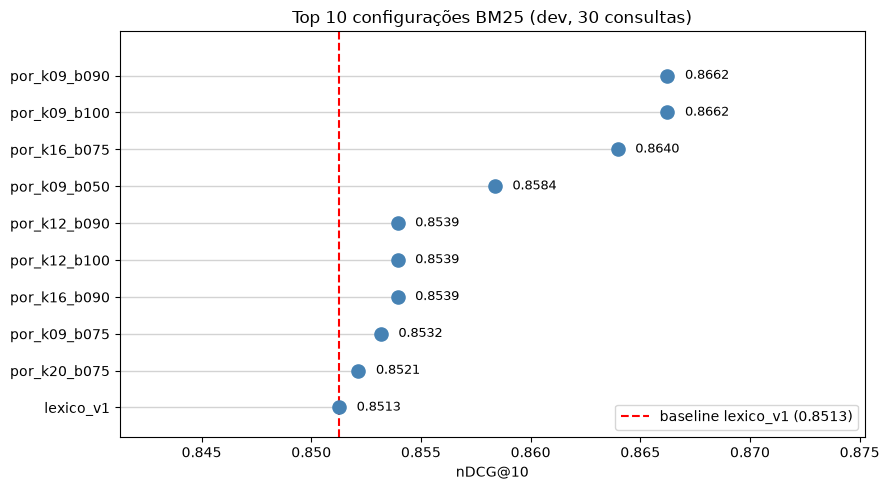

  experiment   analyzer  bm25_k1  bm25_b  ndcg@10  recall@100   mrr@10
por_k09_b090 portuguese      0.9    0.90 0.866238    0.966667 0.855556
por_k09_b100 portuguese      0.9    1.00 0.866238    0.966667 0.855556
por_k16_b075 portuguese      1.6    0.75 0.863970    0.966667 0.842593
por_k09_b050 portuguese      0.9    0.50 0.858372    0.966667 0.835317
por_k12_b090 portuguese      1.2    0.90 0.853936    0.966667 0.838889
por_k12_b100 portuguese      1.2    1.00 0.853936    0.966667 0.838889
por_k16_b090 portuguese      1.6    0.90 0.853936    0.966667 0.838889
por_k09_b075 portuguese      0.9    0.75 0.853173    0.966667 0.838095
por_k20_b075 portuguese      2.0    0.75 0.852149    0.966667 0.826389
   lexico_v1 portuguese      1.2    0.75 0.851269    0.966667 0.825556


In [42]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv(COMPARISON)
df = df.drop_duplicates(subset="experiment", keep="last")

top = (df.sort_values(["ndcg@10", "recall@100", "mrr@10"], ascending=False)
         .head(10)
         .iloc[::-1])                   

baseline = df.loc[df["experiment"] == "lexico_v1", "ndcg@10"]

fig, ax = plt.subplots(figsize=(9, 5))
ax.hlines(y=top["experiment"], xmin=top["ndcg@10"].min() - 0.01,
          xmax=top["ndcg@10"], color="lightgray", linewidth=1)   # linha guia
ax.scatter(top["ndcg@10"], top["experiment"], s=90, color="steelblue", zorder=3)

for y, v in zip(top["experiment"], top["ndcg@10"]):
    ax.text(v + 0.0008, y, f"{v:.4f}", va="center", fontsize=9)

if len(baseline):
    ax.axvline(baseline.iloc[0], color="red", linestyle="--",
               label=f"baseline lexico_v1 ({baseline.iloc[0]:.4f})")
    ax.legend(loc="lower right")

xs = list(top["ndcg@10"]) + ([baseline.iloc[0]] if len(baseline) else [])

span = max(xs) - min(xs)
ax.set_xlim(min(xs) - 0.06 * span, max(xs) + 0.12 * span)

ax.set_xlim(min(xs) - 0.01, max(xs) + 0.009)
ax.set_ylim(-0.8, len(top) + 0.2)          

ax.set_xlabel("nDCG@10")
ax.set_title("Top 10 configurações BM25 (dev, 30 consultas)")
ax.grid(False)                            
plt.tight_layout()
plt.show()

print(top.iloc[::-1].to_string(index=False))

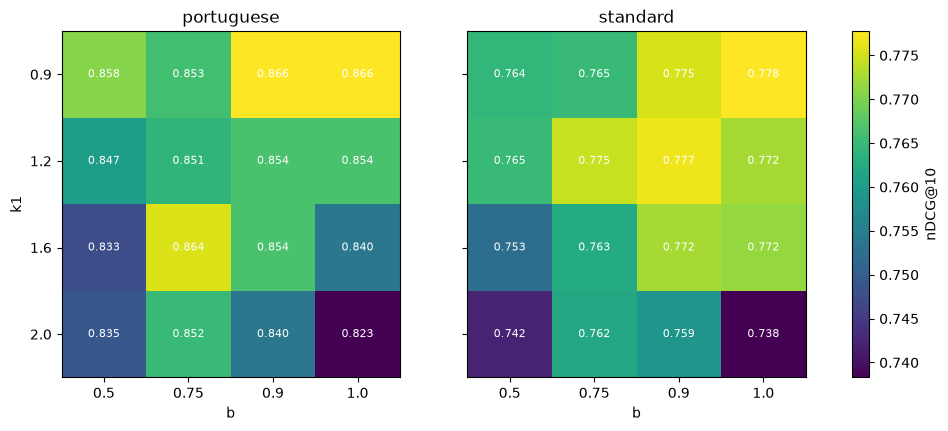

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)

for ax, analyzer in zip(axes, ["portuguese", "standard"]):
    sub = df[df["analyzer"] == analyzer]
    pivot = sub.pivot_table(index="bm25_k1", columns="bm25_b", values="ndcg@10")
    im = ax.imshow(pivot.values, cmap="viridis", aspect="auto")
    ax.set_xticks(range(len(pivot.columns)), pivot.columns)
    ax.set_yticks(range(len(pivot.index)), pivot.index)
    ax.set_xlabel("b")
    ax.set_title(analyzer)
    for i in range(pivot.shape[0]):
        for j in range(pivot.shape[1]):
            ax.text(j, i, f"{pivot.values[i, j]:.3f}", ha="center", va="center", color="white", fontsize=8)

axes[0].set_ylabel("k1")
fig.colorbar(im, ax=axes, label="nDCG@10")
plt.show()

In [43]:
FINE = {
    make_name("portuguese", k1, b): dict(analyzer="portuguese", bm25_k1=k1, bm25_b=b)
    for k1, b in [(0.7, 0.90), (0.8, 0.95), (0.9, 0.95)]
}
for k, v in FINE.items():
    print(k, v)

fine_results = [r for r in (run_one(n, **p) for n, p in FINE.items()) if r]


por_k07_b090 {'analyzer': 'portuguese', 'bm25_k1': 0.7, 'bm25_b': 0.9}
por_k08_b095 {'analyzer': 'portuguese', 'bm25_k1': 0.8, 'bm25_b': 0.95}
por_k09_b095 {'analyzer': 'portuguese', 'bm25_k1': 0.9, 'bm25_b': 0.95}


In [44]:
fine_results

[{'experiment': 'por_k07_b090',
  'analyzer': 'portuguese',
  'bm25_k1': 0.7,
  'bm25_b': 0.9,
  'ndcg@10': 0.8539355564750313,
  'recall@100': 0.9666666666666667,
  'mrr@10': 0.8388888888888889},
 {'experiment': 'por_k08_b095',
  'analyzer': 'portuguese',
  'bm25_k1': 0.8,
  'bm25_b': 0.95,
  'ndcg@10': 0.8662378980226494,
  'recall@100': 0.9666666666666667,
  'mrr@10': 0.8555555555555556},
 {'experiment': 'por_k09_b095',
  'analyzer': 'portuguese',
  'bm25_k1': 0.9,
  'bm25_b': 0.95,
  'ndcg@10': 0.8662378980226494,
  'recall@100': 0.9666666666666667,
  'mrr@10': 0.8555555555555556}]

## CONFIG FINAL ESCOLHIDA ## 

In [47]:
from os_retrieval import run_experiment, OpenSearchHTTP
EXPERIMENT = "lexical_v2"
CONFIG = json.loads((ROOT / "starter/config.json").read_text(encoding="utf-8"))
CONFIG.update(team_id=TEAM, mode="lexical", analyzer="portuguese", bm25_k1=0.9, bm25_b=0.90)
DATA = ROOT / "data/dev"
OUT = ROOT / "resultados" / f"{TEAM}_{EXPERIMENT}"
INDEX = f"ri-{TEAM}-{EXPERIMENT}"
COMPARISON = ROOT / "resultados/comparison_lab4.csv"
OpenSearchHTTP().check()

{'name': '7e175bddd54f',
 'cluster_name': 'docker-cluster',
 'cluster_uuid': 'Iy0FclX_RZSx_NQPFUjL3g',
 'version': {'distribution': 'opensearch',
  'number': '3.9.0',
  'build_type': 'tar',
  'build_hash': '4ee42a94e87f66fbf1e62a9871b1b87f91e02472',
  'build_date': '2026-09-23T01:01:31.883915140Z',
  'build_snapshot': False,
  'lucene_version': '10.5.1',
  'minimum_wire_compatibility_version': '2.19.0',
  'minimum_index_compatibility_version': '2.0.0'},
 'tagline': 'The OpenSearch Project: https://opensearch.org/'}

In [48]:
meta = run_experiment(DATA, OUT, CONFIG, INDEX)
print(meta)

{'backend': 'opensearch', 'server': {'distribution': 'opensearch', 'number': '3.9.0', 'build_type': 'tar', 'build_hash': '4ee42a94e87f66fbf1e62a9871b1b87f91e02472', 'build_date': '2026-09-23T01:01:31.883915140Z', 'build_snapshot': False, 'lucene_version': '10.5.1', 'minimum_wire_compatibility_version': '2.19.0', 'minimum_index_compatibility_version': '2.0.0'}, 'config': {'team_id': 'equipe_16', 'analyzer': 'portuguese', 'bm25_k1': 0.9, 'bm25_b': 0.9, 'title_boost': 1.0, 'mode': 'lexical', 'candidate_k': 100, 'rrf_k': 60}, 'index': {'index': 'ri-equipe_16-lexical_v2', 'documents': 10000, 'dimension': None}, 'corpus_sha256': '11d03c09cc6fe841c328680a19f350a1155c8f7678329bd7f76413523313d76e', 'queries_sha256': 'e70c7b7abe3cc489b9d47092f31fbf00c416a2eaec7ecc192d31217ca32bd5f3', 'run_sha256': 'a8ce2f19ea1aee42f64c26da53fb6972ab68dd811cb0cf8ac4f3451c62f08a18', 'models': {}}


In [49]:
docs, queries = load_data(DATA)
_, ranking = load_run(OUT / "run.csv", docs, queries)
qrels = load_qrels(DATA / "qrels.csv",docs,queries)
per_query, summary = evaluate(ranking,queries,qrels)
write_json(OUT / "metrics.json",summary)
write_csv(OUT / "per_query.csv",list(per_query[0]),per_query)
import csv
COMPARISON = ROOT / "resultados/comparison_lab4.csv"
row = dict(experiment=EXPERIMENT,analyzer=CONFIG["analyzer"],bm25_k1=CONFIG["bm25_k1"],bm25_b=CONFIG["bm25_b"],**{k:summary[k] for k in ["ndcg@10","recall@100","mrr@10"]})
with COMPARISON.open("a",encoding="utf-8",newline="") as f:
    writer=csv.DictWriter(f,fieldnames=list(row))
    if f.tell()==0: writer.writeheader()
    writer.writerow(row)

print(summary, "Comparação:", COMPARISON)

{'ndcg@10': 0.8662378980226494, 'mrr@10': 0.8555555555555556, 'recall@100': 0.9666666666666667, 'judged@10': 0.09000000000000001, 'queries': 30, 'missing_queries': 0} Comparação: /home/oliveirat/disciplinas/reqinfo/RecInfo/lab_ri_opensearch/resultados/comparison_lab4.csv


Execute ao menos duas configurações, mudando `EXPERIMENT` e o analyzer ou parâmetros BM25. Anote métricas e escolha a versão final no README_EQUIPE.md.
 O `run.py` recebe `--data`, `--out` e `--index`. A pasta gerada abaixo é apenas o início da entrega: acrescente comparison.csv, README_EQUIPE.md e dependências próprias.
 A organização congelará o código antes de executar o teste agregado.

In [51]:
DELIVERY = ROOT / "entregas" / f"{TEAM}_phase1_solution"
fresh(DELIVERY)
shutil.copy2(ROOT / "starter/run.py", DELIVERY / "run.py")
for module in ["os_retrieval.py", "ri_core.py", "ri_workflow.py"]:
    shutil.copy2(ROOT / module, DELIVERY / module)
write_json(DELIVERY / "config.json", CONFIG)
shutil.copy2(ROOT / "starter/README_EQUIPE_LAB4.md", DELIVERY / "README_EQUIPE.md")
shutil.copy2(ROOT / "starter/requirements-extra.txt", DELIVERY / "requirements-extra.txt")
(DELIVERY / "resultados_dev").mkdir()
shutil.copy2(COMPARISON, DELIVERY / "resultados_dev/comparison.csv")
print("Pasta inicial da entrega; complete os arquivos exigidos no README:", DELIVERY)

Pasta inicial da entrega; complete os arquivos exigidos no README: /home/oliveirat/disciplinas/reqinfo/RecInfo/lab_ri_opensearch/entregas/equipe_16_phase1_solution
